# Homework #6 – Decision Trees and Ensemble Learning

Dataset: `car_fuel_efficiency_2026.csv`. Target: `fuel_efficiency_mpg`.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer
from sklearn.tree import DecisionTreeRegressor, export_text
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import root_mean_squared_error

In [2]:
URL = 'https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/car_fuel_efficiency_2026.csv'
LOCAL = 'car_fuel_efficiency_2026.csv'

df = pd.read_csv(LOCAL if os.path.exists(LOCAL) else URL)
df.shape

(10000, 11)

In [3]:
df.head()

,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
0,2006,Europe,Gasoline,Front-wheel drive,4,2180,6,243.0,3870,NaN,31.9
1,2008,Europe,Diesel,Front-wheel drive,4,2390,6,272.0,4210,NaN,31.3
2,1996,Asia,Gasoline,Front-wheel drive,5,2320,6,267.0,4240,17.3,27.5
3,1989,Europe,Gasoline,Front-wheel drive,4,2130,6,258.0,4490,18.7,28.5
4,1994,USA,Diesel,Front-wheel drive,3,2580,7,304.0,4510,17.5,31.0


## Preparing the dataset

Fill missing values with zeros, split with `random_state=1`, and vectorize with `DictVectorizer(sparse=True)`.

In [4]:
df.isna().sum()

model_year               0
origin                   0
fuel_type                0
drivetrain               0
num_doors                0
engine_displacement      0
num_cylinders            0
horsepower             877
vehicle_weight           0
acceleration           264
fuel_efficiency_mpg      0
dtype: int64

In [5]:
df = df.fillna(0)
target = 'fuel_efficiency_mpg'

df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_train.pop(target).values
y_val = df_val.pop(target).values
y_test = df_test.pop(target).values

len(df_train), len(df_val), len(df_test)

(6000, 2000, 2000)

In [6]:
dv = DictVectorizer(sparse=True)
X_train = dv.fit_transform(df_train.to_dict(orient='records'))
X_val = dv.transform(df_val.to_dict(orient='records'))

feature_names = list(dv.get_feature_names_out())
feature_names

['acceleration',
 'drivetrain=All-wheel drive',
 'drivetrain=Front-wheel drive',
 'drivetrain=Rear-wheel drive',
 'engine_displacement',
 'fuel_type=Diesel',
 'fuel_type=Gasoline',
 'fuel_type=Hybrid',
 'horsepower',
 'model_year',
 'num_cylinders',
 'num_doors',
 'origin=Asia',
 'origin=Europe',
 'origin=USA',
 'vehicle_weight']

## Question 1

Decision tree with `max_depth=1`. Which original feature is used for the split?

In [7]:
dt = DecisionTreeRegressor(max_depth=1)
dt.fit(X_train, y_train)

print(export_text(dt, feature_names=feature_names))

|--- model_year <= 1997.50
|   |--- value: [28.61]
|--- model_year >  1997.50
|   |--- value: [31.17]



In [8]:
split_feature = feature_names[dt.tree_.feature[0]]
original_column = split_feature.split('=')[0]   # e.g. 'origin=USA' -> 'origin'
print('Split on:', split_feature)
print('Answer Q1:', original_column)

Split on: model_year
Answer Q1: model_year


## Question 2

Random forest with `n_estimators=10`, `random_state=1`.

In [9]:
rf = RandomForestRegressor(n_estimators=10, random_state=1, n_jobs=-1)
rf.fit(X_train, y_train)

rmse_q2 = root_mean_squared_error(y_val, rf.predict(X_val))
print('Validation RMSE:', rmse_q2)
print('Answer Q2:', round(rmse_q2, 3))

Validation RMSE: 1.8332197358745623
Answer Q2: 1.833


## Question 3

Try `n_estimators` in `[10, 50, 100, 150]` (RMSE to 3 decimals).

In [10]:
q3 = []
for n in [10, 50, 100, 150]:
    rf = RandomForestRegressor(n_estimators=n, random_state=1, n_jobs=-1)
    rf.fit(X_train, y_train)
    score = round(root_mean_squared_error(y_val, rf.predict(X_val)), 3)
    q3.append((n, score))
    print(f'n_estimators={n:<4} RMSE={score}')

q3 = pd.DataFrame(q3, columns=['n_estimators', 'rmse'])

n_estimators=10   RMSE=1.833
n_estimators=50   RMSE=1.774
n_estimators=100  RMSE=1.77
n_estimators=150  RMSE=1.769


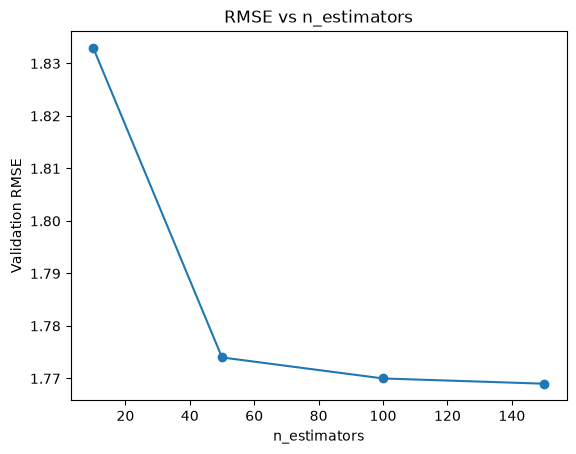

In [11]:
plt.plot(q3.n_estimators, q3.rmse, marker='o')
plt.xlabel('n_estimators')
plt.ylabel('Validation RMSE')
plt.title('RMSE vs n_estimators')
plt.show()

In [12]:
# lowest RMSE; on a tie, the smallest n_estimators
best_n = q3.sort_values(['rmse', 'n_estimators']).iloc[0].n_estimators
print('Answer Q3:', int(best_n))

Answer Q3: 150


## Question 4

For each `max_depth` in `[10, 15, 20, 25]`, try `n_estimators` in `[10, 50, 100, 150]` and take the mean RMSE.

In [13]:
q4 = []
for depth in [10, 15, 20, 25]:
    for n in [10, 50, 100, 150]:
        rf = RandomForestRegressor(n_estimators=n, max_depth=depth, random_state=1, n_jobs=-1)
        rf.fit(X_train, y_train)
        score = root_mean_squared_error(y_val, rf.predict(X_val))
        q4.append((depth, n, score))

q4 = pd.DataFrame(q4, columns=['max_depth', 'n_estimators', 'rmse'])
q4.pivot(index='n_estimators', columns='max_depth', values='rmse').round(4)

max_depth,10,15,20,25
n_estimators,,,,
10,1.7823,1.8314,1.8373,1.8369
50,1.7475,1.7709,1.7724,1.7721
100,1.7440,1.7679,1.7689,1.7683
150,1.7437,1.7668,1.7685,1.7679


In [14]:
mean_rmse = q4.groupby('max_depth').rmse.mean()
print(mean_rmse.round(4))
print('Answer Q4:', mean_rmse.idxmin())

max_depth
10    1.7544
15    1.7842
20    1.7868
25    1.7863
Name: rmse, dtype: float64
Answer Q4: 10


## Question 5

Feature importance from a random forest with `n_estimators=10`, `max_depth=20`, `random_state=1`.

In [15]:
rf = RandomForestRegressor(n_estimators=10, max_depth=20, random_state=1, n_jobs=-1)
rf.fit(X_train, y_train)

importances = pd.Series(rf.feature_importances_, index=feature_names).sort_values(ascending=False)
importances.to_frame('importance')

,importance
model_year,0.296107
vehicle_weight,0.203313
fuel_type=Gasoline,0.160712
horsepower,0.078271
engine_displacement,0.061281
acceleration,0.054998
origin=USA,0.042152
drivetrain=Front-wheel drive,0.020062
num_doors,0.019401
fuel_type=Diesel,0.016571


In [16]:
candidates = ['vehicle_weight', 'horsepower', 'acceleration', 'engine_displacement']
print(importances[candidates].sort_values(ascending=False))
print('Answer Q5:', importances[candidates].idxmax())

vehicle_weight         0.203313
horsepower             0.078271
engine_displacement    0.061281
acceleration           0.054998
dtype: float64
Answer Q5: vehicle_weight


## Question 6

XGBoost with `eta=0.3` vs `eta=0.1`, 100 rounds. Install it first if needed: `pip install xgboost`.

In [17]:
import xgboost as xgb

dtrain = xgb.DMatrix(X_train, label=y_train, feature_names=feature_names)
dval = xgb.DMatrix(X_val, label=y_val, feature_names=feature_names)

watchlist = [(dtrain, 'train'), (dval, 'val')]

def train_xgb(eta):
    xgb_params = {
        'eta': eta,
        'max_depth': 6,
        'min_child_weight': 1,

        'objective': 'reg:squarederror',
        'nthread': 8,

        'seed': 1,
        'verbosity': 1,
    }
    evals_result = {}
    model = xgb.train(xgb_params, dtrain, num_boost_round=100,
                      evals=watchlist, evals_result=evals_result, verbose_eval=False)
    rmse = root_mean_squared_error(y_val, model.predict(dval))
    return rmse, evals_result['val']['rmse']

eta=0.3  validation RMSE = 1.8265
eta=0.1  validation RMSE = 1.7248


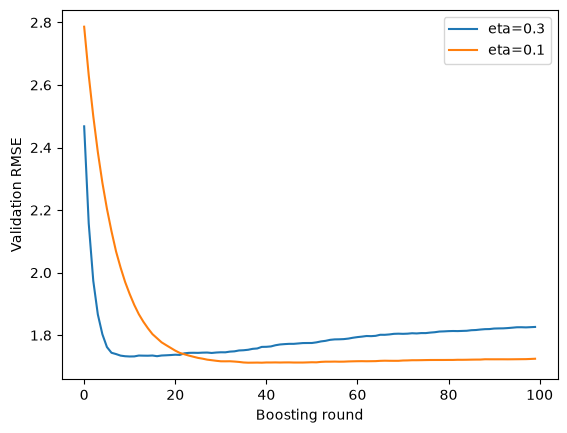

In [18]:
rmse_03, curve_03 = train_xgb(0.3)
rmse_01, curve_01 = train_xgb(0.1)

print(f'eta=0.3  validation RMSE = {rmse_03:.4f}')
print(f'eta=0.1  validation RMSE = {rmse_01:.4f}')

plt.plot(curve_03, label='eta=0.3')
plt.plot(curve_01, label='eta=0.1')
plt.xlabel('Boosting round')
plt.ylabel('Validation RMSE')
plt.legend()
plt.show()

In [19]:
if round(rmse_03, 3) == round(rmse_01, 3):
    print('Answer Q6: Both give equal value')
else:
    print('Answer Q6:', 0.3 if rmse_03 < rmse_01 else 0.1)

Answer Q6: 0.1
